In [1]:
# Author: Till Zemann
# License: MIT License

from __future__ import annotations

import os

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.nn import functional as F
from torch import optim
from tqdm import tqdm

import gymnasium as gym
import pickle as pkl
print(torch.__version__)
from net.a2c import A2C
# gen_a2c_table_bold_sci.py
from pathlib import Path

1.12.0


In [2]:
# simple_type = 'rnn'
# simple_type = 'lstm'
simple_type = 'linear'
ei_type = 'eisep'
# task_name = 'halfcheetah'
task_name = 'lunarlander'
colors = ['#FA7F72', '#A84499', '#183319', '#20B2AA']
config_names = ['Simple', 'EISep(A)', 'EISep(C)', 'EISep(A+C)']
npy_path = Path(f"./rl/result/{task_name}/simple_{simple_type}_ei_{ei_type}/reward_ars.npy")

reward_ars = np.load(npy_path)
print(reward_ars.shape)

FileNotFoundError: [Errno 2] No such file or directory: 'rl/result/lunarlander/simple_linear_ei_eisep/reward_ars.npy'

In [ ]:
### ALL lr

# ===== Your settings =====
actor_lrs  = [0.0003, 0.001, 0.003]
critic_lrs = [0.0015, 0.005, 0.015]
configurations = ['simple', 'eisep_actor', 'eisep_critic', 'eisep_all']  # top->bottom order

# out_tex  = Path("./rl/result/lunarlander/simple_rnn_ei_eisep/a2c_lunarlander_table.tex")
out_tex = Path(f"./rl/result/{task_name}/simple_{simple_type}_ei_{ei_type}/a2c_{task_name}_lr_sweep_table.tex")

# ===== Load & aggregate =====
reward_ars = np.load(npy_path)
reward_ar_flatten = reward_ars.reshape(
    len(actor_lrs), len(critic_lrs), len(configurations), -1
)
mean_r = reward_ar_flatten.mean(axis=-1)
ste_r  = reward_ar_flatten.std(axis=-1, ddof=0) / np.sqrt(reward_ar_flatten.shape[-1])

config_names   = ['Simple', 'EISep(A)', 'EISep(C)', 'EISep(A+C)']  # for caption text

# Input / output
out_tex  = Path(f"./rl/result/{task_name}/simple_{simple_type}_ei_{ei_type}/a2c_{task_name}_lr_sweep_table.tex")

# Seeds description (for caption)
N_TRAIN_SEEDS = 5
N_TEST_SEEDS  = 20


A, C, K = mean_r.shape
assert K == len(configurations), f"K mismatch: mean_r has K={K}, but configurations has {len(configurations)}"

# ==================================
# ===== Formatting helpers ==========
# ==================================
def fmt_num(x: float) -> str:
    return f"{x:.2f}"

def fmt_lr(x: float) -> str:
    """Return scientific notation in LaTeX form, e.g., 3e-4 -> 3\\times10^{-4}."""
    x = float(x)
    if x == 0:
        return "0"
    exp = int(np.floor(np.log10(abs(x))))
    base = x / (10 ** exp)
    # Use g to avoid trailing zeros, keep it compact
    return f"{base:g}\\times10^{{{exp}}}"

def bold_math(math_text: str) -> str:
    """
    Input like '$12.34 \\pm 0.56$' and return bold math.
    We keep it in math mode and apply \\mathbf to the whole content.
    """
    t = math_text.strip()
    if t.startswith("$") and t.endswith("$"):
        t = t[1:-1]
    return f"$\\mathbf{{{t}}}$"

# ==========================================================
# ===== Find best (actor_lr, critic_lr) per configuration ====
# ==========================================================
# For each model k, find the lr pair (i,j) that maximizes mean reward.
# If ties happen, we bold all cells achieving the same maximum (within tolerance).
best_mask = np.zeros((A, C, K), dtype=bool)
for k in range(K):
    mx = np.max(mean_r[:, :, k])
    # tolerance for floating comparisons
    best_mask[:, :, k] = np.isclose(mean_r[:, :, k], mx, rtol=1e-12, atol=1e-12)

# =========================================
# ===== Build one table cell (4 lines) =====
# =========================================
def cell_block(i_actor: int, j_critic: int) -> str:
    """
    Create a 4-line makecell. For each config k:
      show mean±SE, and bold it if (i_actor, j_critic) is that config's best lr pair.
    """
    lines = []
    for k in range(K):
        m = fmt_num(mean_r[i_actor, j_critic, k])
        s = fmt_num(ste_r[i_actor, j_critic, k])
        txt = f"${m} \\pm {s}$"
        if best_mask[i_actor, j_critic, k]:
            txt = bold_math(txt)
        lines.append(txt)
    return "\\makecell[tc]{" + "\\\\[1pt]".join(lines) + "}"

# =========================
# ===== Build LaTeX =======
# =========================
lines = []
lines.append("\\begin{table}[t]")
lines.append("  \\centering")
lines.append("  \\caption{Learning-rate sweep on LunarLander. Each cell reports test return (mean $\\pm$ SE) for four model variants (top to bottom): "
             + ", ".join(config_names)
             + f". Boldface marks the best learning-rate pair for each model (searched over the whole grid). "
             + f"Each configuration uses $n={N_TRAIN_SEEDS}$ training seeds and each trained model is evaluated with $n={N_TEST_SEEDS}$ test seeds."
             + "}")
lines.append("  \\label{tab:lunarlander_lr_sweep}")
lines.append("  \\setlength{\\tabcolsep}{3pt}")
lines.append("  \\renewcommand{\\arraystretch}{0.9}")
lines.append("  \\scriptsize")
lines.append("  \\begin{tabular}{l" + "c"*len(actor_lrs) + "}")
lines.append("    \\toprule")

actor_hdr = " & ".join([f"$\\mathbf{{{fmt_lr(a)}}}$" for a in actor_lrs])
lines.append(f"    \\textbf{{lr(C) $\\backslash$ lr(A)}} & {actor_hdr} \\\\")
lines.append("    \\midrule")

for j, c_lr in enumerate(critic_lrs):
    row_cells = [f"$\\mathbf{{{fmt_lr(c_lr)}}}$"]
    for i in range(len(actor_lrs)):
        row_cells.append(cell_block(i, j))
    lines.append("    " + " & ".join(row_cells) + " \\\\")
    if j < len(critic_lrs) - 1:
        lines.append("    \\midrule")

lines.append("    \\bottomrule")
lines.append("  \\end{tabular}")
lines.append("")
lines.append("  \\vspace{3pt}")
lines.append("  \\textit{Order in each cell (top to bottom):} "
             + ", ".join(config_names) + ".")
lines.append("\\end{table}")

out_tex.parent.mkdir(parents=True, exist_ok=True)
out_tex.write_text("\n".join(lines), encoding="utf-8")
print(out_tex.resolve())
print('./'+str(out_tex))


/home/geert/neurogym/docs/examples/rl/result/halfcheetah/simple_lstm_ei_eisep/a2c_halfcheetah_lr_sweep_table.tex
./rl/result/halfcheetah/simple_lstm_ei_eisep/a2c_halfcheetah_lr_sweep_table.tex


[OK] Saved: result/lunarlander/simple_rnn_ei_fixed_entryei/a2c_heatmaps_per_config.*
[OK] Saved: result/lunarlander/simple_rnn_ei_fixed_entryei/a2c_heatmap_best_over_config.*


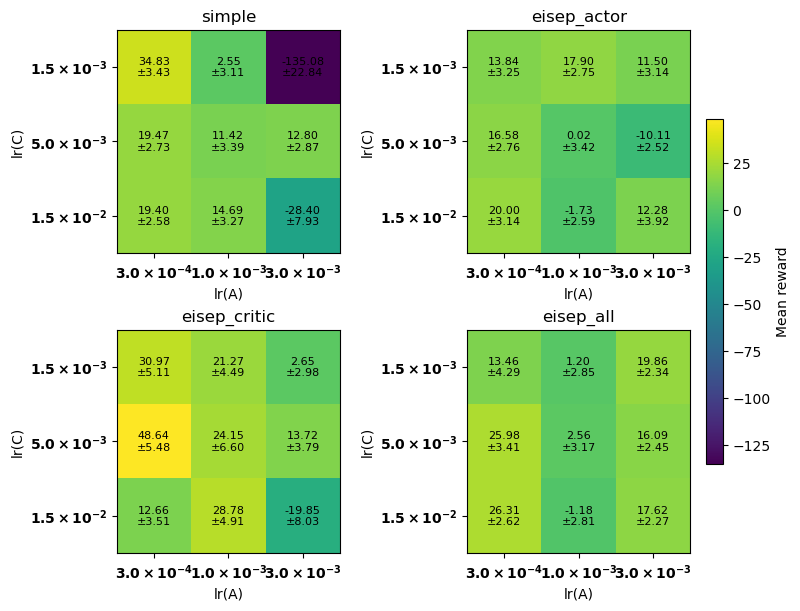

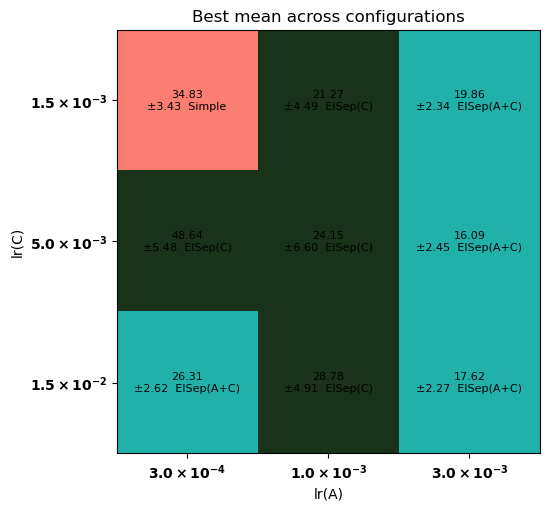

In [ ]:
# gen_a2c_heatmaps.py
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.patches as mpatches
# ===== Your settings =====
actor_lrs  = [0.0003, 0.001, 0.003]
critic_lrs = [0.0015, 0.005, 0.015]
configurations = ['simple', 'eisep_actor', 'eisep_critic', 'eisep_all']  # order matters
short_cfg = ['Simple', 'EISep(A)', 'EISep(C)', 'EISep(A+C)']

out_dir  = Path("./result/lunarlander/simple_rnn_ei_fixed_entryei")
out_dir.mkdir(parents=True, exist_ok=True)

# ===== Load & aggregate =====
reward_ars = np.load(npy_path)  # any original shape as long as totals match
reward_ar_flatten = reward_ars.reshape(
    len(actor_lrs), len(critic_lrs), len(configurations), -1
)  # [actor, critic, config, trial]
mean_r = reward_ar_flatten.mean(axis=-1)  # [actor, critic, config]
ste_r  = reward_ar_flatten.std(axis=-1, ddof=0) / np.sqrt(reward_ar_flatten.shape[-1])

# ===== Helpers =====
def sci_lr(x: float) -> str:
    """Return LR as TeX-like '1.0×10^{-3}' wrapped in math mode for nice ticks."""
    exp = int(np.floor(np.log10(x)))
    base = x / (10 ** exp)
    return rf"$\mathbf{{{base:.1f}\times10^{{{exp}}}}}$"

def annotate_cell(ax, i_row, j_col, text, fontsize=8):
    ax.text(j_col, i_row, text, ha='center', va='center', fontsize=fontsize)

def grid_from_config(k_cfg: int):
    """
    Return (M_mean, M_se) for one configuration as [rows=critic, cols=actor].
    mean_r[:,:,k] is [actor, critic]; transpose to [critic, actor].
    """
    M_mean = mean_r[:, :, k_cfg].T
    M_se   = ste_r[:, :, k_cfg].T
    return M_mean, M_se

# Shared color scale across all configs for fair visual comparison
all_means = np.concatenate([grid_from_config(k)[0].ravel() for k in range(len(configurations))])
vmin, vmax = float(np.nanmin(all_means)), float(np.nanmax(all_means))

# ===== (1) 2×2 heatmaps: one per configuration =====
fig, axes = plt.subplots(2, 2, figsize=(8, 6), constrained_layout=True)
axes = axes.ravel()

for k, cfg in enumerate(configurations):
    ax = axes[k]
    M_mean, M_se = grid_from_config(k)

    im = ax.imshow(M_mean, vmin=vmin, vmax=vmax, aspect='equal')  # default cmap
    # Annotations: "mean±SE" with two decimals
    for r in range(M_mean.shape[0]):           # rows = critic
        for c in range(M_mean.shape[1]):       # cols = actor
            annotate_cell(ax, r, c, f"{M_mean[r, c]:.2f}\n±{M_se[r, c]:.2f}", fontsize=8)

    # Ticks with scientific notation labels
    ax.set_xticks(np.arange(len(actor_lrs)))
    ax.set_yticks(np.arange(len(critic_lrs)))
    ax.set_xticklabels([sci_lr(a) for a in actor_lrs], rotation=0)
    ax.set_yticklabels([sci_lr(c) for c in critic_lrs])

    ax.set_xlabel(r"lr(A)")
    ax.set_ylabel(r"lr(C)")
    ax.set_title(cfg)

# One shared colorbar
cbar = fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02)
cbar.set_label("Mean reward")

fig.savefig(out_dir / "a2c_heatmaps_per_config.png", dpi=300)
fig.savefig(out_dir / "a2c_heatmaps_per_config.pdf")
print("[OK] Saved:", out_dir / "a2c_heatmaps_per_config.*")

# ===== (2) Best-over-config heatmap =====
# For each (actor, critic), find best config by mean; build grid with best means and labels
best_idx_ac = np.argmax(mean_r, axis=-1)    # shape [actor, critic]
best_mean_ac = np.max(mean_r, axis=-1)      # shape [actor, critic]
best_se_ac   = ste_r[np.arange(len(actor_lrs))[:,None],
                     np.arange(len(critic_lrs))[None,:],
                     best_idx_ac]           # matching SEs

# Convert to [critic, actor] for plotting
best_mean_grid = best_mean_ac.T
best_se_grid   = best_se_ac.T
best_idx_grid  = best_idx_ac.T  # integers in [0..3]


cmap = ListedColormap(colors)
norm = BoundaryNorm(boundaries=[-0.5, 0.5, 1.5, 2.5, 3.5], ncolors=4)

fig2, ax2 = plt.subplots(1, 1, figsize=(6, 5), constrained_layout=True)
im2 = ax2.imshow(best_idx_grid,  cmap=cmap, norm=norm, aspect='equal')

# Annotate with "mean±SE (CFG)"
for r in range(best_mean_grid.shape[0]):
    for c in range(best_mean_grid.shape[1]):
        cfg_lab = short_cfg[int(best_idx_grid[r, c])]
        annotate_cell(ax2, r, c, f"{best_mean_grid[r, c]:.2f}\n±{best_se_grid[r, c]:.2f}  {cfg_lab}", fontsize=8)

ax2.set_xticks(np.arange(len(actor_lrs)))
ax2.set_yticks(np.arange(len(critic_lrs)))
ax2.set_xticklabels([sci_lr(a) for a in actor_lrs])
ax2.set_yticklabels([sci_lr(c) for c in critic_lrs])
ax2.set_xlabel(r"lr(A)")
ax2.set_ylabel(r"lr(C)")
ax2.set_title("Best mean across configurations")
patches = [mpatches.Patch(color=colors[i], label=config_names[i]) for i in range(4)]
# ax2.legend(handles=patches, loc='upper left', frameon=False)
# cbar2 = fig2.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)
# cbar2.set_label("Mean reward")

fig2.savefig(out_dir / "a2c_heatmap_best_over_config.png", dpi=300)
fig2.savefig(out_dir / "a2c_heatmap_best_over_config.pdf")
print("[OK] Saved:", out_dir / "a2c_heatmap_best_over_config.*")


./rl/result/lunarlander/simple_linear_ei_eisep/best_reward_per_model.png


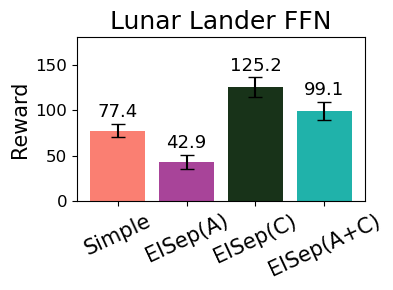

In [ ]:
# gen_a2c_heatmaps.py
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.patches as mpatches
from rl.rl_util import savefig
# ===== Your settings =====
actor_lrs  = [0.0003, 0.001, 0.003]
critic_lrs = [0.0015, 0.005, 0.015]
configurations = ['simple', 'eisep_actor', 'eisep_critic', 'eisep_all']  # order matters
# simple_type = 'rnn'
# simple_type = 'lstm'
simple_type = 'linear'
ei_type = 'eisep'
task_name = 'lunarlander'
colors = ['#FA7F72', '#A84499', '#183319', '#20B2AA']
config_names = ['Simple', 'EISep(A)', 'EISep(C)', 'EISep(A+C)']
npy_path = Path(f"./rl/result/{task_name}/simple_{simple_type}_ei_{ei_type}/reward_ars.npy")

# ===== Load & aggregate =====
reward_ars = np.load(npy_path)  # any original shape as long as totals match
reward_ar_flatten = reward_ars.reshape(
    len(actor_lrs), len(critic_lrs), len(configurations), -1
)  # [actor, critic, config, trial]
mean_r = reward_ar_flatten.mean(axis=-1).reshape(-1, len(config_names))  # [actor, critic, config]
ste_r  = reward_ar_flatten.std(axis=-1, ddof=0).reshape(-1, len(config_names)) / np.sqrt(reward_ar_flatten.shape[-1])

best_idx = np.argmax(mean_r, axis=0)  # per config
best_mean_r = mean_r[best_idx, np.arange(len(config_names))]
best_ste_r  = ste_r[best_idx, np.arange(len(config_names))]
fig, ax = plt.subplots(figsize=(4,3))
fontsize = 15
bars = ax.bar(config_names, best_mean_r, yerr=best_ste_r, color=colors, capsize=5)
ax.bar_label(bars, fmt='%.1f', padding=2, fontsize=fontsize-2)
ax.set_ylim(0, 180)
# ax.set_ylim(0, 5200)
ax.set_title('Lunar Lander', fontsize=fontsize+3)
# ax.set_title('HalfCheetah', fontsize=fontsize+3)
# ax.set_xlabel('Model', fontsize=fontsize)
ax.set_xticks(np.arange(len(config_names)), config_names, fontsize=fontsize, rotation=25)
ax.set_ylabel('Reward', fontsize=fontsize)
ax.tick_params(labelsize=fontsize-3, axis='y')
ax.tick_params(labelsize=fontsize, axis='x')
plt.tight_layout()
# plt.show()

savefig(f"./rl/result/{task_name}/simple_{simple_type}_ei_{ei_type}/best_reward_per_model.png")


./rl/result/lunarlander/best_reward_per_model.pdf


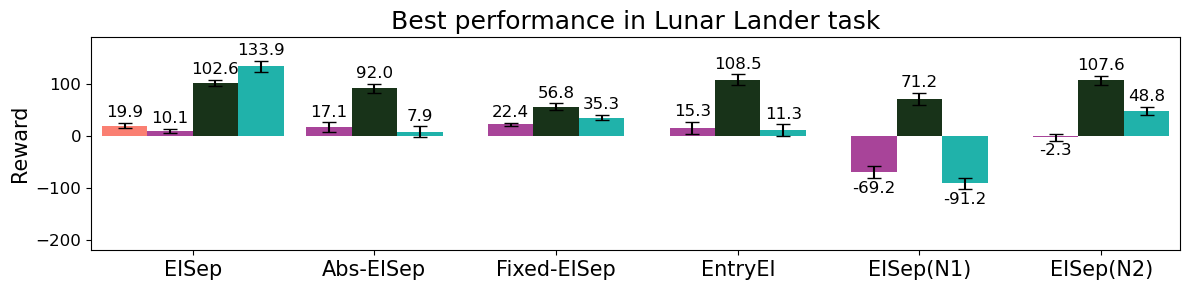

In [ ]:
# gen_a2c_heatmaps.py
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.patches as mpatches
from rl.rl_util import savefig
# ===== Your settings =====
actor_lrs  = [0.0003, 0.001, 0.003]
critic_lrs = [0.0015, 0.005, 0.015]
configurations = ['simple', 'eisep_actor', 'eisep_critic', 'eisep_all']  # order matters
simple_type = 'rnn'
ei_type = 'eisep'
task_name = 'lunarlander'
colors = ['#FA7F72', '#A84499', '#183319', '#20B2AA']
config_names = ['Simple', 'EI(A)', 'EI(C)', 'EI(A+C)']
npy_path = Path(f"./rl/result/{task_name}/simple_{simple_type}_ei_{ei_type}/reward_ars.npy")
# model_names = ['simple_rnn_ei_eisep', 'simple_rnn_ei_absolute_eisep', 'simple_rnn_ei_fixed_eisep', 'simple_rnn_ei_entryei',
#                'simple_rnn_ei_eisep_init_ColEI', 'simple_rnn_ei_eisep_init_DBPN']
model_names = ['simple_rnn_ei_eisep', 'NoEnt_1.0_simple_rnn_ei_eisep']
# model_names = ['simple_rnn_ei_eisep', 'simple_rnn_ei_dann_sgd', 'simple_rnn_ei_dann_adam',
#                'simple_rnn_ei_colei_sgd', 'simple_rnn_ei_colei_adam', 'simple_rnn_ei_dbpn']
# model_names = ['simple_lstm_ei_eisep', 'simple_lstm_ei_noshare_eisep']
paths = [Path(f"./rl/result/{task_name}/{mn}/reward_ars.npy") for mn in model_names]
# model_names_present = ['EISep', 'Abs-EISep', 'Fixed-EISep', 'EntryEI', 'EISep(N1)', 'EISep(N2)']
# model_names_present = ['EISep', 'DANN-SGD', 'DANN-Adam', 'ColEI-SGD', 'ColEI-Adam', 'DBPN']
model_names_present = ['EISep', 'EISep-NoEnt']
# ===== Load & aggregate =====
best_mean_rs = np.zeros((len(paths), len(config_names)))
best_ste_rs  = np.zeros((len(paths), len(config_names)))
for i, path in enumerate(paths):
    reward_ars = np.load(path)
    reward_ar_flatten = reward_ars.reshape(
        len(actor_lrs), len(critic_lrs), len(configurations), -1
    )  # [actor, critic, config, trial]
    mean_r = reward_ar_flatten.mean(axis=-1).reshape(-1, len(config_names))  # [actor, critic, config]

    ste_r  = reward_ar_flatten.std(axis=-1, ddof=0).reshape(-1, len(config_names)) / np.sqrt(reward_ar_flatten.shape[-1])

    best_idx = np.argmax(mean_r, axis=0)  # per config
    best_mean_r = mean_r[best_idx, np.arange(len(config_names))]
    best_ste_r  = ste_r[best_idx, np.arange(len(config_names))]
    best_mean_rs[i] = best_mean_r
    best_ste_rs[i]  = best_ste_r

fig, ax = plt.subplots(1, 1, figsize=(2*len(best_mean_rs)+2,3))
fontsize = 15
width = 1
n_config = best_mean_rs.shape[1]
n_variant = best_mean_rs.shape[0]
# for i in range(n_config):  # per config
#     if i == 0: #only draw simple on the first group
#         positions = (i - n_config/2) * (width / n_config) + width/(2*n_config)
#         bars = ax.bar(
#             positions,
#             best_mean_rs[0, i],
#             yerr=best_ste_rs[0, i],
#             width=width / best_mean_rs.shape[1],
#             color=colors[i],
#             capsize=5,
#             label=config_names[i]
#         )
#     else: # only draw 3
#         positions = np.arange(n_variant) + (i - (n_config)/2) * (width / (n_config)) + width/(2*(n_config)) * np.array([1,0,0,0])

#         bars = ax.bar(
#             positions,
#             best_mean_rs[:, i],
#             yerr=best_ste_rs[:, i],
#             width=width / best_mean_rs.shape[1],
#             color=colors[i],
#             capsize=5,
#             label=config_names[i]
#         )
#     ax.bar_label(bars, fmt='%.1f', padding=2, fontsize=fontsize-3)
bar_width = width / n_config
for i in range(n_variant):  # per model
    if i == 0:
        positions = (np.arange(n_config) - n_config/2+1/2) * bar_width + i
        bars = ax.bar(
            positions,
            best_mean_rs[i],
            yerr=best_ste_rs[i],
            width=bar_width,
            color=colors,
            capsize=5,
            label=config_names
        )
    else:
        positions = (np.arange(n_config-1) - (n_config-1)/2+1/2) * bar_width + i
        bars = ax.bar(
            positions,
            best_mean_rs[i,1:],
            yerr=best_ste_rs[i,1:],
            width=bar_width,
            color=colors[1:],
            capsize=5,
            label=config_names[1:]
        )
    ax.bar_label(bars, fmt='%.1f', padding=2, fontsize=fontsize-3)

    # if i == 0:
    #     ax.legend(ncol=1, fontsize=fontsize-3, loc='upper center')

# ax.set_ylim(0, 170)
ax.set_ylim(-220, 190)
ax.set_title('Best performance in Lunar Lander task', fontsize=fontsize+3)
ax.set_xmargin(0.01)
# ax.set_xlabel('Model', fontsize=fontsize)
ax.set_xticks(np.arange(len(model_names_present)), model_names_present, fontsize=fontsize)
ax.set_ylabel('Reward', fontsize=fontsize)
ax.tick_params(axis='y', labelsize=fontsize-3)
plt.tight_layout()
# plt.show()
figpath = './rl/result/lunarlander/best_reward_per_model.png'
savefig(figpath)
# savefig(f"./rl/result/lunarlander/simple_{simple_type}_ei_{ei_type}/best_reward_per_model.png")


./rl/result/lunarlander/actor_critic_legend.png


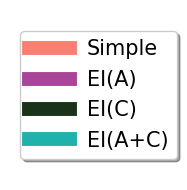

In [ ]:
# fig, ax = plt.subplots(1,1,figsize=(4,2))
# fig, ax = plt.subplots(1,1,figsize=(8,1))
fig, ax = plt.subplots(1,1,figsize=(2,2))
colors = ['#FA7F72', '#A84499', '#183319', '#20B2AA']
config_names = ['Simple', 'EI(A)', 'EI(C)', 'EI(A+C)']
for i in range(len(config_names)):
    ax.plot([], [], color=colors[i], label=config_names[i], linewidth=10)
ax.legend(fontsize=15, loc='center left', framealpha=1, shadow=True, markerscale=1, ncol=1)
ax.axis('off')
plt.tight_layout()
figpath = './rl/result/lunarlander/actor_critic_legend.png'
savefig(figpath)

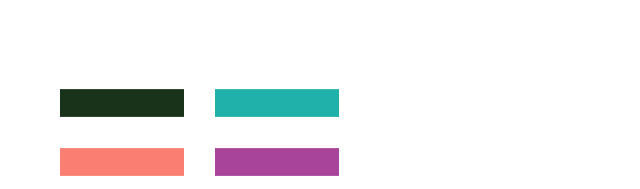

In [ ]:
import matplotlib.pyplot as plt

def draw_actor_critic_legend(colors, config_names,
                             figsize=(8, 2.2), fontsize=26, linew=20,
                             outpath=None):

    # 显式映射（非常重要，避免歧义）
    cfg = {
        ("Simple", "Simple"): (config_names[0], colors[0]),  # Simple
        ("Simple", "EI"):  (config_names[1], colors[1]),  # EI(A)
        ("EI",  "Simple"): (config_names[2], colors[2]),  # EI(C)
        ("EI",  "EI"):  (config_names[3], colors[3]),  # EI(A+C)
    }

    fig, ax = plt.subplots(figsize=figsize)
    ax.set_axis_off()
    ax.set_xlim(-0.1, 0.9)
    ax.set_ylim(-0.1, 0.9)

    # ===== 布局参数（只需要改这些就能微调） =====
    x_col = [0, 0.25]     # Actor: Holistic / Modular
    y_row = [0, 0.35]     # Critic: Holistic / Modular
    x_rowlab = 0.33
    seg_len = 0.2

    # ===== Actor 标题 + 括号 =====
    # ax.text(sum(x_col)/2, 0.92, "Actor", ha="center", va="center",
    #         fontsize=fontsize)

    # ax.annotate(
    #     "", xy=(x_col[1] + 0.10, 0.88), xytext=(x_col[0] - 0.10, 0.88),
    #     arrowprops=dict(arrowstyle="-[", lw=1.2, mutation_scale=25)
    # )

    # ax.text(x_col[0], 0.76, "Holistic", ha="center", va="center",
    #         fontsize=fontsize, color=colors[0])
    # ax.text(x_col[1], 0.76, "Modular", ha="center", va="center",
    #         fontsize=fontsize, color=colors[3])

    # ===== Critic 标题 + 括号 =====
    # ax.text(0.09, sum(y_row)/2, "Critic", ha="center", va="center",
    #         fontsize=fontsize)

    # ax.annotate(
    #     "", xy=(0.16, y_row[0] + 0.10), xytext=(0.16, y_row[1] - 0.10),
    #     arrowprops=dict(arrowstyle="-[", lw=1.2, mutation_scale=25)
    # )

    # ax.text(x_rowlab, y_row[0], "Holistic", ha="right", va="center",
    #         fontsize=fontsize, color=colors[0])
    # ax.text(x_rowlab, y_row[1], "Modular", ha="right", va="center",
    #         fontsize=fontsize, color=colors[3])

    # ===== 四个 configuration 的短横线 =====
    def draw_seg(x, y, color):
        ax.plot([x, x + seg_len], [y, y],
                lw=linew, color=color, solid_capstyle="butt")

    for i, critic in enumerate(["Simple", "EI"]):
        for j, actor in enumerate(["Simple", "EI"]):
            _, c = cfg[(critic, actor)]
            draw_seg(x_col[j] - 0.02, y_row[i], c)

    if outpath is not None:
        fig.savefig(outpath, dpi=400, bbox_inches="tight", pad_inches=0.02)

    return fig, ax
draw_actor_critic_legend(
    colors=['#FA7F72', '#A84499', '#183319', '#20B2AA'],
    config_names=['Simple', 'EI(A)', 'EI(C)', 'EI(A+C)'],
    outpath="./rl/output/actor_critic_legend.png"
)
plt.show()


#### Use best variant

./rl/result/lunarlander/bib.png


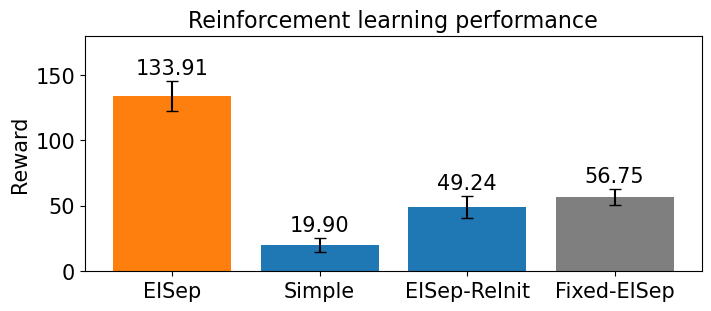

In [6]:
# gen_a2c_heatmaps.py
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.patches as mpatches
from rl.rl_util import savefig
# ===== Your settings =====
actor_lrs  = [0.0003, 0.001, 0.003]
critic_lrs = [0.0015, 0.005, 0.015]
configurations = ['simple', 'eisep_actor', 'eisep_critic', 'eisep_all']  # order matters
simple_type = 'rnn'
ei_type = 'eisep'
task_name = 'lunarlander'
# colors = ['#FA7F72', '#A84499', '#183319', '#20B2AA']
# colors = ['C1', 'C0', 'C7', 'C8', 'C9', '#E69F00','#009E73', 'black']
colors = ['C1', 'C0', 'C0', 'C7']
config_names = ['Simple', 'EI(A)', 'EI(C)', 'EI(A+C)']
# npy_path = Path(f"./rl/result/{task_name}/simple_{simple_type}_ei_{ei_type}/reward_ars.npy")
# model_names = ['simple_rnn_ei_eisep', 'simple_rnn_ei_absolute_eisep', 'simple_rnn_ei_fixed_eisep', 'simple_rnn_ei_entryei',
#                'simple_rnn_ei_eisep_init_ColEI', 'simple_rnn_ei_eisep_init_DBPN']
# model_names = ['simple_rnn_ei_eisep', 'simple_rnn_ei_dann_sgd', 'simple_rnn_ei_dann_adam',
#                'simple_rnn_ei_colei_sgd', 'simple_rnn_ei_colei_adam', 'simple_rnn_ei_dbpn']
# model_names = ['simple_lstm_ei_eisep', 'simple_lstm_ei_noshare_eisep']
model_names = ['simple_rnn_ei_eisep', 'simple_rnn_ei_eisep_reinit', 'simple_rnn_ei_fixed_eisep']
paths = [Path(f"./rl/result/{task_name}/{mn}/reward_ars.npy") for mn in model_names]
# model_names_present = ['EISep', 'Simple', 'Abs-EISep', 'Fixed-EISep', 'EntryEI', 'EISep(N1)', 'EISep(N2)', 'Cstr-Simple']
# model_names_present = ['EISep', 'DANN-SGD', 'DANN-Adam', 'ColEI-SGD', 'ColEI-Adam', 'DBPN']
model_names_present = ['EISep', 'Simple', 'EISep-ReInit', 'Fixed-EISep']

# ===== Load & aggregate =====
best_mean_rs = np.zeros((len(paths), len(config_names)))
best_ste_rs  = np.zeros((len(paths), len(config_names)))
for i, path in enumerate(paths):
    reward_ars = np.load(path)
    # (len(actor_lrs), len(critic_lrs), len(configurations), n_seed, n_showcase_episodes)
    if reward_ars.shape[2] == len(configurations):
        reward_ar_flatten = reward_ars.reshape(
            len(actor_lrs), len(critic_lrs), len(configurations), 100
        )  # [actor, critic, config, trial]
    else:
        reward_ar_flatten = np.concatenate([np.zeros((len(actor_lrs), len(critic_lrs), 1, 100)),
                reward_ars.reshape(len(actor_lrs), len(critic_lrs), len(configurations)-1, 100)], -2)  # [actor, critic, config, trial]
    mean_r = reward_ar_flatten.mean(axis=-1).reshape(-1, len(config_names))  # [actor*critic, config]

    ste_r  = reward_ar_flatten.std(axis=-1, ddof=0).reshape(-1, len(config_names)) / np.sqrt(reward_ar_flatten.shape[-1])

    best_idx = np.argmax(mean_r, axis=0)  # per config
    best_mean_r = mean_r[best_idx, np.arange(len(config_names))]
    best_ste_r  = ste_r[best_idx, np.arange(len(config_names))]
    best_mean_rs[i] = best_mean_r
    best_ste_rs[i]  = best_ste_r

bib_idx = np.argmax(best_mean_rs[:, 1:], axis=1)+1  # per model, skip simple
bib_mean_r = best_mean_rs[np.arange(len(paths)), bib_idx]
bib_ste_r  = best_ste_rs[np.arange(len(paths)), bib_idx]


bib_mean_r_include_simple = list(bib_mean_r)
bib_ste_r_include_simple  = list(bib_ste_r)
bib_mean_r_include_simple.insert(1, best_mean_rs[0,0])
bib_ste_r_include_simple.insert(1, best_ste_rs[0,0])

# add cstr_simple
# reward_cstr_simple = np.load(f"./rl/result/lunarlander/simple_cstr_rnn_ei_eisep/reward_ars.npy")[:,:,0,...]
# reward_cstr_simple_flatten = reward_cstr_simple.reshape(len(actor_lrs)*len(critic_lrs), 100)
# mean_r_cstr_simple = reward_cstr_simple_flatten.mean(axis=-1)  # [actor*critic, config]
# ste_r_cstr_simple  = reward_cstr_simple_flatten.std(axis=-1, ddof=0) / np.sqrt(reward_cstr_simple_flatten.shape[-1])
# best_idx_cstr_simple = np.argmax(mean_r_cstr_simple)  # per config
# print(best_idx_cstr_simple)
# best_mean_r_cstr_simple = mean_r_cstr_simple[best_idx_cstr_simple]
# best_ste_r_cstr_simple  = ste_r_cstr_simple[best_idx_cstr_simple]
# bib_mean_r_include_simple.append(best_mean_r_cstr_simple)
# bib_ste_r_include_simple.append(best_ste_r_cstr_simple)

bib_mean_r_final = np.array(bib_mean_r_include_simple)
bib_ste_r_final  = np.array(bib_ste_r_include_simple)
# print(bib_mean_r_final, best_mean_r_cstr_simple, best_ste_r_cstr_simple, type(bib_mean_r_include_simple))


fig, ax = plt.subplots(figsize=(7,3), constrained_layout=True)


for i in range(len(model_names_present)):
    bars = ax.bar(i, bib_mean_r_final[i], yerr=bib_ste_r_final[i], capsize=4, color=colors[i])
    ax.bar_label(bars, fmt='%.2f', padding=2, fontsize=15)
ax.set_xticks(np.arange(len(model_names_present)))
# ax.set_xticklabels(model_names_present, rotation=30, ha='right', fontsize=12)
ax.set_xticklabels(model_names_present, fontsize=12)
ax.set_title('Reinforcement learning performance', fontsize=16)
ax.set_ylabel('Reward', fontsize=15)
ax.set_ylim(0,180)
ax.tick_params(labelsize=15)

figpath = './rl/result/lunarlander/bib.png'
savefig(figpath)

Multi-eie coef

[ 89.47637072  95.2517029  133.90967159  93.06841586]
./rl/output/lunarlander/multieie_final_performance.png


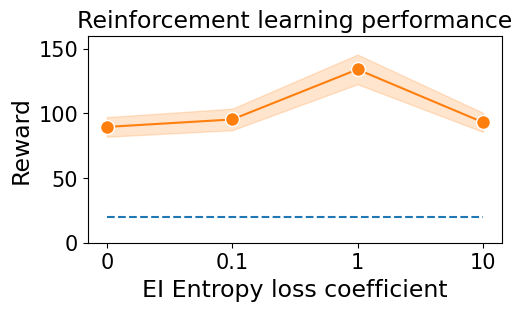

In [ ]:
# gen_a2c_heatmaps.py
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.patches as mpatches
from rl.rl_util import savefig
# ===== Your settings =====
actor_lrs  = [0.0003, 0.001, 0.003]
critic_lrs = [0.0015, 0.005, 0.015]
configurations = ['eisep_actor', 'eisep_critic', 'eisep_all']  # order matters
simple_type = 'rnn'
ei_type = 'eisep'
task_name = 'lunarlander'
# colors = ['#FA7F72', '#A84499', '#183319', '#20B2AA']
# colors = ['C1', 'C0', 'C7', 'C8', 'C9', '#E69F00','#009E73', 'black']
colors = ['C1', 'C0', 'C0', 'C7']
config_names = ['EI(A)', 'EI(C)', 'EI(A+C)']
eie_coefficients = [0, 0.1, 10]
paths = [Path(f"./rl/result/{task_name}/Ent_{eie_coef}_simple_rnn_ei_eisep/reward_ars.npy") for eie_coef in eie_coefficients]

# ===== Load & aggregate =====
best_mean_rs = np.zeros((len(paths)+1, len(config_names)))
best_ste_rs  = np.zeros((len(paths)+1, len(config_names)))
reward_ars = [np.load(path) for path in paths]
origin_ar = np.load(Path(f"./rl/result/{task_name}/simple_rnn_ei_eisep/reward_ars.npy")).reshape(len(actor_lrs), len(critic_lrs), len(configurations)+1, 100)
eisep_ar = origin_ar[:,:,1:]
reward_ars.insert(2, eisep_ar)

for i, reward_ar in enumerate(reward_ars):
    # (len(actor_lrs), len(critic_lrs), len(configurations), n_seed, n_showcase_episodes)
    reward_ar_flatten = reward_ar.reshape(len(actor_lrs), len(critic_lrs), len(configurations), 100) # [actor, critic, config, trial]
    mean_r = reward_ar_flatten.mean(axis=-1).reshape(-1, len(config_names))  # [actor*critic, config]
    ste_r  = reward_ar_flatten.std(axis=-1, ddof=0).reshape(-1, len(config_names)) / np.sqrt(reward_ar_flatten.shape[-1])
    best_idx = np.argmax(mean_r, axis=0)  # per config
    best_mean_r = mean_r[best_idx, np.arange(len(config_names))]
    best_ste_r  = ste_r[best_idx, np.arange(len(config_names))]
    best_mean_rs[i] = best_mean_r
    best_ste_rs[i]  = best_ste_r

bib_idx = np.argmax(best_mean_rs, axis=1)  # per model
bib_mean_r = best_mean_rs[np.arange(len(reward_ars)), bib_idx]
bib_ste_r  = best_ste_rs[np.arange(len(reward_ars)), bib_idx]

simple_ar = origin_ar[:,:,:1]
simple_ar_flatten = simple_ar.reshape(len(actor_lrs), len(critic_lrs), 1, 100)
simple_mean_r = simple_ar_flatten.mean(axis=-1).reshape(-1)  # [actor*critic]
simple_ste_r  = simple_ar_flatten.std(axis=-1, ddof=0).reshape(-1) / np.sqrt(simple_ar_flatten.shape[-1])
best_simple_idx = np.argmax(simple_mean_r)
best_simple_mean_r = simple_mean_r[best_simple_idx]
best_simple_ste_r = simple_ste_r[best_simple_idx]

eie_coefficients_final = [0, 0.1, 1, 10]
bib_mean_r_final = np.array(bib_mean_r)
bib_ste_r_final  = np.array(bib_ste_r)
# print(bib_mean_r_final, best_mean_r_cstr_simple, best_ste_r_cstr_simple, type(bib_mean_r_include_simple))
print(bib_mean_r_final)


fontsize = 15
fig, ax = plt.subplots(1,1,figsize=(5,3), constrained_layout=True)
ax.plot(np.arange(len(eie_coefficients_final)), bib_mean_r_final, color='C1',
        marker='o', markersize=10, markeredgecolor='white', markeredgewidth=1)
ax.fill_between(np.arange(len(eie_coefficients_final)),
                bib_mean_r_final - bib_ste_r_final, bib_mean_r_final + bib_ste_r_final, alpha=0.2, color='C1')
ax.set_ylim(0,160)
ax.set_xticks(np.arange(len(eie_coefficients_final)))
ax.set_xticklabels(eie_coefficients_final)
# ax[0].set_xlabel('Hidden size', fontsize=fontsize+2)
ax.set_xlabel('EI Entropy loss coefficient', fontsize=fontsize+2)
ax.set_title('Reinforcement learning performance', fontsize=fontsize+2)
# ax[0].legend(loc='lower right', fontsize=fontsize)
ax.set_ylabel('Reward', fontsize=fontsize+2)
ax.tick_params(labelsize=fontsize)
ax.hlines(best_simple_mean_r, 0, len(eie_coefficients_final)-1, colors='C0', linestyles='--')

savefig(f'./rl/output/{task_name}/multieie_final_performance.png', dpi=400)
plt.show()
plt.close()
# ax.set_xticks(np.arange(len(model_names_present)))
# ax.set_xticklabels(model_names_present, rotation=30, ha='right', fontsize=12)
# ax.set_xticklabels(model_names_present, fontsize=12)
# ax.set_title('Reinforcement learning performance', fontsize=16)
# ax.set_ylabel('Reward', fontsize=15)
# ax.set_ylim(0,180)
# ax.tick_params(labelsize=15)

# figpath = './rl/result/lunarlander/bib.png'
# savefig(figpath)

In [ ]:
bib_mean_r_final_new = np.delete(bib_mean_r_final, 1, 0)
bib_ste_r_final_new  = np.delete(bib_ste_r_final,1,0)

fig, ax = plt.subplots(figsize=(6,3), constrained_layout=True)
model_names_present = ['EISep', 'EISep-NoEnt']
for i in range(len(model_names_present)):
    bars = ax.bar(i, bib_mean_r_final_new[i], yerr=bib_ste_r_final_new[i], capsize=4, color=colors[i])
    ax.bar_label(bars, fmt='%.2f', padding=2, fontsize=15)
ax.set_xticks(np.arange(len(model_names_present)))
ax.set_xticklabels(model_names_present, rotation=0, ha='center', fontsize=12)
# ax.set_xticklabels(legend_names[:len(model_names)], fontsize=12)
ax.set_title('Reinforcement learning performance', fontsize=16)
ax.set_ylabel('Reward', fontsize=15)
ax.set_ylim(0,180)
ax.tick_params(labelsize=15)

figpath = './rl/result/lunarlander/bib.png'
savefig(figpath)

best_mean_rs = np.zeros((len(paths), len(config_names)))
best_ste_rs  = np.zeros((len(paths), len(config_names)))
best_all_rs = np.zeros((len(paths), len(config_names), 100))
for i, path in enumerate(paths):
    reward_ars = np.load(path)
    if reward_ars.shape[2] == len(configurations):
        reward_ar_flatten = reward_ars.reshape(
            len(actor_lrs), len(critic_lrs), len(configurations), 100
        )  # [actor, critic, config, trial]
    else:
        reward_ar_flatten = np.concatenate([np.zeros((len(actor_lrs), len(critic_lrs), 1, 100)),
                reward_ars.reshape(len(actor_lrs), len(critic_lrs), len(configurations)-1, 100)], -2)
    mean_r = reward_ar_flatten.mean(axis=-1).reshape(-1, len(config_names))  # [actor, critic, config]

    ste_r  = reward_ar_flatten.std(axis=-1, ddof=0).reshape(-1, len(config_names)) / np.sqrt(reward_ar_flatten.shape[-1])

    best_idx = np.argmax(mean_r, axis=0)  # per config
    best_mean_r = mean_r[best_idx, np.arange(len(config_names))]
    best_ste_r  = ste_r[best_idx, np.arange(len(config_names))]
    best_mean_rs[i] = best_mean_r
    best_ste_rs[i]  = best_ste_r
    best_all_rs[i] = reward_ar_flatten.reshape(
        len(actor_lrs)*len(critic_lrs), len(configurations), 100
    )[best_idx, np.arange(len(config_names))]
bib_idx = np.argmax(best_mean_rs[:, 1:], axis=1)+1  # per model, skip simple
bib_mean_r = best_mean_rs[np.arange(len(paths)), bib_idx]
bib_ste_r  = best_ste_rs[np.arange(len(paths)), bib_idx]
bib_all_r = best_all_rs[np.arange(len(paths)), bib_idx, :]
rs1 = bib_all_r[0]
rs2 = bib_all_r[1]
from scipy.stats import ttest_rel

t_stat, p_value = ttest_rel(rs1, rs2)
print('t:', t_stat, 'p:', p_value)

Cstr-Simple


(3, 3, 4, 5, 20)
./rl/result/lunarlander/bib.png


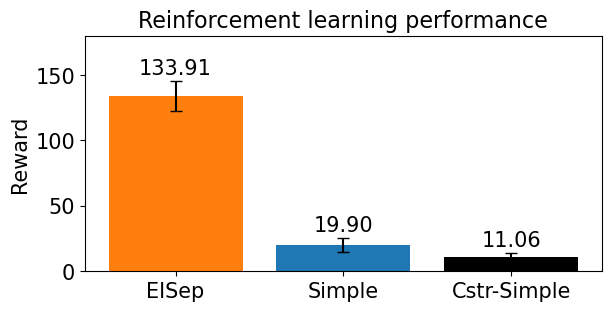

In [ ]:
# gen_a2c_heatmaps.py
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.patches as mpatches
from rl.rl_util import savefig
# ===== Your settings =====
actor_lrs  = [0.0003, 0.001, 0.003]
critic_lrs = [0.0015, 0.005, 0.015]
configurations = ['simple', 'eisep_actor', 'eisep_critic', 'eisep_all']  # order matters
simple_type = 'rnn'
ei_type = 'eisep'
task_name = 'lunarlander'
# colors = ['#FA7F72', '#A84499', '#183319', '#20B2AA']
colors = ['C1', 'C0', 'black']
config_names = ['Simple', 'EI(A)', 'EI(C)', 'EI(A+C)']
npy_path = Path(f"./rl/result/{task_name}/simple_{simple_type}_ei_{ei_type}/reward_ars.npy")
model_names = ['simple_rnn_ei_eisep', 'simple_cstr_rnn_ei_eisep']
# model_names = ['simple_rnn_ei_eisep', 'simple_rnn_ei_dann_sgd', 'simple_rnn_ei_dann_adam',
#                'simple_rnn_ei_colei_sgd', 'simple_rnn_ei_colei_adam', 'simple_rnn_ei_dbpn']
# model_names = ['simple_lstm_ei_eisep', 'simple_lstm_ei_noshare_eisep']
paths = [Path(f"./rl/result/{task_name}/{mn}/reward_ars.npy") for mn in model_names]
model_names_present = ['EISep', 'Simple', 'Cstr-Simple']
# model_names_present = ['EISep', 'DANN-SGD', 'DANN-Adam', 'ColEI-SGD', 'ColEI-Adam', 'DBPN']
# model_names_present = ['EISep', 'NS-EISep']
# ===== Load & aggregate =====
best_mean_rs = []
best_ste_rs  = []
lengths = [4, 1]
reward_arrays = np.zeros((len(model_names_present), len(actor_lrs)*len(critic_lrs), 100))
print(np.load(paths[0]).shape)
reward_arrays[0] = np.load(paths[0])[:,:,-1,...].reshape(len(actor_lrs)*len(critic_lrs), 100)
reward_arrays[1] = np.load(paths[0])[:,:,0,...].reshape(len(actor_lrs)*len(critic_lrs), 100)
reward_arrays[2] = np.load(paths[1])[:,:,0,...].reshape(len(actor_lrs)*len(critic_lrs), 100)

mean_r = reward_arrays.mean(axis=-1).reshape(len(model_names_present), len(actor_lrs)*len(critic_lrs))  # [actor, critic, config]
ste_r  = reward_arrays.std(axis=-1, ddof=0).reshape(len(model_names_present), len(actor_lrs)*len(critic_lrs)) / np.sqrt(reward_arrays.shape[-1])


best_idx = np.argmax(mean_r, axis=-1)  # per config
best_mean_r = mean_r[np.arange(len(model_names_present)), best_idx]
best_ste_r  = ste_r[np.arange(len(model_names_present)), best_idx]



fig, ax = plt.subplots(figsize=(6,3), constrained_layout=True)


for i in range(len(model_names_present)):
    bars = ax.bar(i, best_mean_r[i], yerr=best_ste_r[i], capsize=4, color=colors[i])
    ax.bar_label(bars, fmt='%.2f', padding=2, fontsize=15)
ax.set_xticks(np.arange(len(model_names_present)))
ax.set_xticklabels(model_names_present, ha='center', fontsize=12)
# ax.set_xticklabels(legend_names[:len(model_names)], fontsize=12)
ax.set_title('Reinforcement learning performance', fontsize=16)
ax.set_ylabel('Reward', fontsize=15)
ax.set_ylim(0,180)
ax.tick_params(labelsize=15)

figpath = './rl/result/lunarlander/bib.png'
savefig(figpath)

(3, 3, 4, 5, 20)
(3, 3, 3, 5, 20)
./rl/result/lunarlander/best_reward_per_model.png


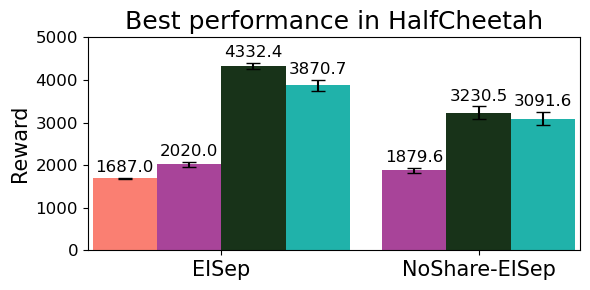

In [ ]:
# gen_a2c_heatmaps.py
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.patches as mpatches
from rl.rl_util import savefig
# ===== Your settings =====
actor_lrs  = [0.0003, 0.001, 0.003]
critic_lrs = [0.0015, 0.005, 0.015]
configurations = ['simple', 'eisep_actor', 'eisep_critic', 'eisep_all']  # order matters
# simple_type = 'rnn'
# ei_type = 'eisep'
simple_type = 'lstm'
ei_type = 'noshare_eisep'
task_name = 'halfcheetah'
colors = ['#FA7F72', '#A84499', '#183319', '#20B2AA']
config_names = ['Simple', 'EI(A)', 'EI(C)', 'EI(A+C)']
npy_path = Path(f"./rl/result/{task_name}/simple_{simple_type}_ei_{ei_type}/reward_ars.npy")
# model_names = ['simple_rnn_ei_eisep', 'simple_rnn_ei_absolute_eisep', 'simple_rnn_ei_fixed_eisep', 'simple_rnn_ei_entryei',
#                'simple_rnn_ei_eisep_init_ColEI', 'simple_rnn_ei_eisep_init_DBPN']
# model_names = ['simple_rnn_ei_eisep', 'simple_rnn_ei_dann_sgd', 'simple_rnn_ei_dann_adam',
#                'simple_rnn_ei_colei_sgd', 'simple_rnn_ei_colei_adam', 'simple_rnn_ei_dbpn']
model_names = ['simple_lstm_ei_eisep', 'simple_lstm_ei_noshare_eisep']
paths = [Path(f"./rl/result/{task_name}/{mn}/reward_ars.npy") for mn in model_names]
# model_names_present = ['EISep', 'Abs-EISep', 'Fixed-EISep', 'EntryEI', 'EISep(N1)', 'EISep(N2)']
# model_names_present = ['EISep', 'DANN-SGD', 'DANN-Adam', 'ColEI-SGD', 'ColEI-Adam', 'DBPN']
model_names_present = ['EISep', 'NoShare-EISep']
# ===== Load & aggregate =====
best_mean_rs = np.zeros((len(paths), len(config_names)))
best_ste_rs  = np.zeros((len(paths), len(config_names)))
for i, path in enumerate(paths):
    reward_ars = np.load(path)
    print(reward_ars.shape)
    if i == 0:
        len_config = len(configurations)
    else:
        len_config = len(configurations) - 1
    reward_ar_flatten = reward_ars.reshape(
        len(actor_lrs), len(critic_lrs), len_config, -1
    )  # [actor, critic, config, trial]
    mean_r = reward_ar_flatten.mean(axis=-1).reshape(-1, len_config)  # [actor, critic, config]

    ste_r  = reward_ar_flatten.std(axis=-1, ddof=0).reshape(-1, len_config) / np.sqrt(reward_ar_flatten.shape[-1])

    best_idx = np.argmax(mean_r, axis=0)  # per config
    best_mean_r = mean_r[best_idx, np.arange(len_config)]
    best_ste_r  = ste_r[best_idx, np.arange(len_config)]
    if i == 0:
        best_mean_rs[i] = best_mean_r
        best_ste_rs[i]  = best_ste_r
    else:
        best_mean_rs[i,1:] = best_mean_r
        best_ste_rs[i,1:]  = best_ste_r

fig, ax = plt.subplots(1, 1, figsize=(3*len(best_mean_rs),3))
fontsize = 15
width = 1
n_config = best_mean_rs.shape[1]
n_variant = best_mean_rs.shape[0]

bar_width = width / n_config
for i in range(n_variant):  # per model
    if i == 0:
        positions = (np.arange(n_config) - n_config/2+1/2) * bar_width + i
        bars = ax.bar(
            positions,
            best_mean_rs[i],
            yerr=best_ste_rs[i],
            width=bar_width,
            color=colors,
            capsize=5,
            label=config_names
        )
    else:
        positions = (np.arange(n_config-1) - (n_config-1)/2+1/2) * bar_width + i
        bars = ax.bar(
            positions,
            best_mean_rs[i,1:],
            yerr=best_ste_rs[i,1:],
            width=bar_width,
            color=colors[1:],
            capsize=5,
            label=config_names[1:]
        )
    ax.bar_label(bars, fmt='%.1f', padding=2, fontsize=fontsize-3)

    # if i == 0:
    #     ax.legend(ncol=1, fontsize=fontsize-3, loc='upper center')

# ax.set_ylim(0, 170)
ax.set_ylim(0, 5000)
ax.set_title('Best performance in HalfCheetah', fontsize=fontsize+3)
ax.set_xmargin(0.01)
# ax.set_xlabel('Model', fontsize=fontsize)
ax.set_xticks(np.arange(len(model_names_present)), model_names_present, fontsize=fontsize)
ax.set_ylabel('Reward', fontsize=fontsize)
ax.tick_params(axis='y', labelsize=fontsize-3)
plt.tight_layout()
# plt.show()
figpath = './rl/result/lunarlander/best_reward_per_model.png'
savefig(figpath)
# savefig(f"./rl/result/lunarlander/simple_{simple_type}_ei_{ei_type}/best_reward_per_model.png")
